# Stage 28: Final Statistical Analysis

This notebook provides the final statistical validation for the dose-response experiments (Stage 26).


In [1]:
import json
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from pathlib import Path

# Set up matplotlib style
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

def get_path(filename):
    paths = [
        Path(filename),
        Path(f"/kaggle/input/datasets/priyansh2006/stage27/{filename}"),
        Path(f"/kaggle/input/priyansh2006/stage27/{filename}"),
        Path(f"/kaggle/input/stage27/{filename}")
    ]
    for p in paths:
        if p.exists():
            return p
    return Path(filename)


## Part 1: Load Data and Build Main Table
We load the K=10 and K=20 JSON records and build a dataset of 50 runs.


In [2]:
records = []
for K in [10, 20]:
    path = get_path(f'stage26_K{K}_confirmatory.json')
    if not path.exists(): continue
    with open(path, 'r') as f:
        data = json.load(f)
    
    rhos = sorted([float(k) for k in data.keys()])
    for rho in rhos:
        rho_str = str(rho) if str(rho) in data else str(float(rho))
        for key in data.keys():
            if abs(float(key) - rho) < 1e-4:
                rho_str = key
                break
        
        for seed in data[rho_str]['summaries']:
            summ = data[rho_str]['summaries'][seed]
            traj = data[rho_str]['trajectories'][seed]
            
            # AUC of log10(RelL2)
            steps = [t['step'] for t in traj]
            log_rels = [np.log10(t['rel_l2']) for t in traj]
            auc = np.trapezoid(log_rels, steps)
            
            # A_0.01 and A_0.001
            a_01 = np.nan
            a_001 = np.nan
            for t in traj:
                if t['rel_l2'] < 1e-2 and np.isnan(a_01):
                    a_01 = t['step']
                if t['rel_l2'] < 1e-3 and np.isnan(a_001):
                    a_001 = t['step']
            
            records.append({
                'K': K,
                'rho': rho,
                'seed': int(seed),
                'final_rel_l2': summ['final_rel_l2'],
                'best_rel_l2': summ['best_rel_l2'],
                'step_of_best': summ['step_of_best'],
                'final_pde_loss': summ['final_pde_loss'],
                'mean_E_update': summ['mean_E_update'],
                'median_E_update': summ['median_E_update'],
                'p90_E_update': summ['p90_E_update'],
                'max_E_update': summ['max_E_update'],
                'AUC': auc,
                'A_0.01': a_01,
                'A_0.001': a_001
            })

df = pd.DataFrame(records)
display(df.head())


,K,rho,seed,final_rel_l2,best_rel_l2,step_of_best,final_pde_loss,mean_E_update,median_E_update,p90_E_update,max_E_update,AUC,A_0.01,A_0.001
0,10,0.0,0,0.000891,0.000400,1930,0.000216,0.0,0.0,0.0,0.0,-3772.882837,950,1280.0
1,10,0.0,1,0.001445,0.000934,1890,0.000053,0.0,0.0,0.0,0.0,-3851.885572,860,1790.0
2,10,0.0,2,0.000629,0.000529,1910,0.000007,0.0,0.0,0.0,0.0,-3957.588307,830,1280.0
3,10,0.0,3,0.000537,0.000432,1880,0.000058,0.0,0.0,0.0,0.0,-3966.112337,860,1220.0
4,10,0.0,4,0.000807,0.000624,1970,0.000019,0.0,0.0,0.0,0.0,-3814.275277,920,1390.0


## Part 2 & Table 1: Paired Effect Relative to Natural MoQ
Calculate paired differences $\Delta_\rho$ relative to natural MoQ, and summarize means and SDs.


In [3]:
table1_records = []
for K in [10, 20]:
    df_k = df[df['K'] == K]
    
    for rho in df_k['rho'].unique():
        rels = df_k[df_k['rho'] == rho]['final_rel_l2'].values
        mean_rel = np.mean(rels)
        sd_rel = np.std(rels, ddof=1)
        
        if rho == 0:
            table1_records.append({
                'K': K, 'rho': rho, 
                'Mean final RelL2': mean_rel, 'SD': sd_rel,
                'Mean Δ RelL2': np.nan, 'Median paired Δ': np.nan
            })
            continue
            
        # Paired differences
        deltas = []
        for seed in range(5):
            r_rho = df_k[(df_k['rho'] == rho) & (df_k['seed'] == seed)]['final_rel_l2'].values[0]
            r_0 = df_k[(df_k['rho'] == 0) & (df_k['seed'] == seed)]['final_rel_l2'].values[0]
            deltas.append(r_rho - r_0)
            
        table1_records.append({
            'K': K, 'rho': rho, 
            'Mean final RelL2': mean_rel, 'SD': sd_rel,
            'Mean Δ RelL2': np.mean(deltas), 'Median paired Δ': np.median(deltas)
        })

df_table1 = pd.DataFrame(table1_records)
print("Table 1 - Final performance")
display(df_table1)


Table 1 - Final performance


,K,rho,Mean final RelL2,SD,Mean Δ RelL2,Median paired Δ
0,10,0.00,0.000862,0.000355,NaN,NaN
1,10,0.25,0.002290,0.000494,0.001429,0.001210
2,10,0.50,0.002029,0.000535,0.001167,0.001169
3,10,0.75,0.002620,0.000438,0.001758,0.001858
4,10,1.00,0.003275,0.000919,0.002413,0.002219
5,20,0.00,0.001068,0.000643,NaN,NaN
6,20,0.25,0.002186,0.000909,0.001119,0.001560
7,20,0.50,0.003001,0.000672,0.001933,0.001985
8,20,0.75,0.003455,0.000366,0.002388,0.002435
9,20,1.00,0.003300,0.000913,0.002233,0.002652


## Part 3 & Table 2: Statistical Test
Wilcoxon signed-rank test for $\rho > 0$ vs $\rho = 0$.


In [4]:
table2_records = []
for K in [10, 20]:
    df_k = df[df['K'] == K]
    for rho in df_k['rho'].unique():
        if rho == 0: continue
        
        deltas = []
        n_plus = 0
        
        for seed in range(5):
            r_rho = df_k[(df_k['rho'] == rho) & (df_k['seed'] == seed)]['final_rel_l2'].values[0]
            r_0 = df_k[(df_k['rho'] == 0) & (df_k['seed'] == seed)]['final_rel_l2'].values[0]
            deltas.append(r_rho - r_0)
            if r_rho > r_0:
                n_plus += 1
                
        # Exact Wilcoxon
        try:
            stat, p = stats.wilcoxon(deltas, alternative="two-sided", method="exact")
        except ValueError:
            p = np.nan
            
        effect_size = np.mean(deltas) / np.std(deltas, ddof=1)
        
        table2_records.append({
            'K': K, 'rho': rho,
            'Mean Δ': np.mean(deltas),
            'Median Δ': np.median(deltas),
            'SD(Δ)': np.std(deltas, ddof=1),
            'n_+ / 5': f"{n_plus}/5",
            'Cohen d_z': effect_size,
            'Exact Wilcoxon p': p
        })

df_table2 = pd.DataFrame(table2_records)
print("Table 2 - Statistical test")
display(df_table2)


Table 2 - Statistical test


,K,rho,Mean Δ,Median Δ,SD(Δ),n_+ / 5,Cohen d_z,Exact Wilcoxon p
0,10,0.25,0.001429,0.001210,0.000535,5/5,2.670595,0.0625
1,10,0.50,0.001167,0.001169,0.000771,5/5,1.513914,0.0625
2,10,0.75,0.001758,0.001858,0.000671,5/5,2.622038,0.0625
3,10,1.00,0.002413,0.002219,0.001150,5/5,2.098645,0.0625
4,20,0.25,0.001119,0.001560,0.001424,4/5,0.785874,0.1875
5,20,0.50,0.001933,0.001985,0.001134,5/5,1.704960,0.0625
6,20,0.75,0.002388,0.002435,0.000713,5/5,3.348235,0.0625
7,20,1.00,0.002233,0.002652,0.001028,5/5,2.171531,0.0625


## Part 3.5: Repeated-Measures Dose Test
Friedman test to evaluate within-seed dose effect.


In [5]:
friedman_records = []
for K in [10, 20]:
    df_k = df[df['K'] == K]
    rhos = sorted(df_k['rho'].unique())
    if len(rhos) < 5: continue
    
    # Collect arrays of length 5 (seeds) for each rho
    data_by_rho = []
    for rho in rhos:
        vals = []
        for seed in range(5):
            val = df_k[(df_k['rho'] == rho) & (df_k['seed'] == seed)]['final_rel_l2'].values[0]
            vals.append(val)
        data_by_rho.append(vals)
        
    stat, p = stats.friedmanchisquare(*data_by_rho)
    
    N = 5
    k = len(rhos)
    W = stat / (N * (k - 1))
        
    friedman_records.append({
        'K': K,
        'Friedman χ²': stat,
        'Friedman p-value': p,
        'Kendall W': W
    })

df_friedman = pd.DataFrame(friedman_records)
print("Friedman Test - Repeated measures dose test")
display(df_friedman)


Friedman Test - Repeated measures dose test


,K,Friedman χ²,Friedman p-value,Kendall W
0,10,15.84,0.003242,0.792
1,20,12.16,0.016200,0.608


## Part 4: Dose-Response Analysis
Seed-level Spearman correlations for $\rho \rightarrow final\ RelL2$ and $\rho \rightarrow \overline{E}_{update}$


In [6]:
for K in [10, 20]:
    df_k = df[df['K'] == K]
    
    corr_l2_list = []
    corr_E_list = []
    
    for seed in range(5):
        seed_df = df_k[df_k['seed'] == seed].sort_values('rho')
        rhos = seed_df['rho'].values
        l2s = seed_df['final_rel_l2'].values
        Es = seed_df['mean_E_update'].values
        
        c_l2, _ = stats.spearmanr(rhos, l2s)
        c_E, _ = stats.spearmanr(rhos, Es)
        
        corr_l2_list.append(c_l2)
        corr_E_list.append(c_E)
        
    print(f"K={K}: Mean Spearman(rho, final_RelL2) = {np.mean(corr_l2_list):.3f}")
    print(f"K={K}: Mean Spearman(rho, mean_E_update) = {np.mean(corr_E_list):.3f}")


K=10: Mean Spearman(rho, final_RelL2) = 0.760
K=10: Mean Spearman(rho, mean_E_update) = 1.000
K=20: Mean Spearman(rho, final_RelL2) = 0.640
K=20: Mean Spearman(rho, mean_E_update) = 1.000


## Part 5: Mechanism -> Outcome
Scatter plot of $\overline{E}_{update}$ vs $\Delta RelL2$ (change from natural MoQ), separated by K.


K=10
  Pearson:  r=0.466 (p=0.0384)
  Spearman: rho=0.436 (p=0.0546)
  Linear slope: 0.01843
K=20
  Pearson:  r=0.381 (p=0.0970)
  Spearman: rho=0.289 (p=0.2170)
  Linear slope: 0.01697


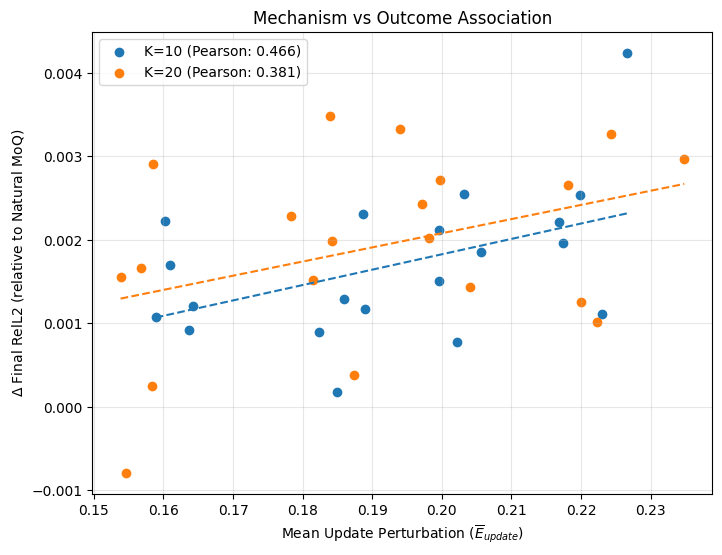

In [7]:
plt.figure(figsize=(8, 6))

for K in [10, 20]:
    g = df[df["K"] == K].copy()
    
    natural = (
        g[g["rho"] == 0][["seed", "final_rel_l2"]]
        .rename(columns={"final_rel_l2": "rel2_nat"})
    )
    
    g = g.merge(natural, on="seed", how="left")
    g["delta_rel2"] = g["final_rel_l2"] - g["rel2_nat"]
    
    nonzero = g[g["rho"] > 0]
    E_vals = nonzero["mean_E_update"].values
    delta_vals = nonzero["delta_rel2"].values
    
    p_corr, p_pval = stats.pearsonr(E_vals, delta_vals)
    s_corr, s_pval = stats.spearmanr(E_vals, delta_vals)
    slope, intercept, r_value, p_value, std_err = stats.linregress(E_vals, delta_vals)

    print(f"K={K}")
    print(f"  Pearson:  r={p_corr:.3f} (p={p_pval:.4f})")
    print(f"  Spearman: rho={s_corr:.3f} (p={s_pval:.4f})")
    print(f"  Linear slope: {slope:.5f}")

    plt.scatter(E_vals, delta_vals, label=f'K={K} (Pearson: {p_corr:.3f})')
    x_line = np.linspace(min(E_vals), max(E_vals), 100)
    plt.plot(x_line, intercept + slope * x_line, '--')

plt.xlabel(r'Mean Update Perturbation ($\overline{E}_{update}$)')
plt.ylabel(r'$\Delta$ Final RelL2 (relative to Natural MoQ)')
plt.title('Mechanism vs Outcome Association')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## Part 6: Training Trajectory Dynamics
Checking $A_{0.01}$ (first step RelL2 < 10^-2) and $A_{0.001}$ (first step RelL2 < 10^-3) and AUC of log10(RelL2).


In [8]:
traj_summary = []
for K in [10, 20]:
    for rho in df['rho'].unique():
        df_sub = df[(df['K'] == K) & (df['rho'] == rho)]
        
        # Calculate fraction reaching 0.001
        reached_001 = df_sub['A_0.001'].notna().sum()
        frac_001 = f"{reached_001}/{len(df_sub)}"
        
        traj_summary.append({
            'K': K, 'rho': rho,
            'Mean AUC_log': df_sub['AUC'].mean(),
            'Mean A_0.01': df_sub['A_0.01'].mean(),
            'Fraction reaching 1e-3': frac_001,
            'Mean A_0.001': df_sub['A_0.001'].mean()
        })
        
display(pd.DataFrame(traj_summary))


,K,rho,Mean AUC_log,Mean A_0.01,Fraction reaching 1e-3,Mean A_0.001
0,10,0.00,-3872.548866,884.0,5/5,1392.0
1,10,0.25,-3425.582783,984.0,1/5,1600.0
2,10,0.50,-3362.003928,1028.0,0/5,NaN
3,10,0.75,-3169.312332,1116.0,0/5,NaN
4,10,1.00,-3118.729361,1148.0,0/5,NaN
5,20,0.00,-3845.736481,888.0,5/5,1466.0
6,20,0.25,-3403.480009,1004.0,1/5,2000.0
7,20,0.50,-3257.983461,1062.0,0/5,NaN
8,20,0.75,-3131.865342,1168.0,0/5,NaN
9,20,1.00,-3070.456353,1172.0,0/5,NaN


## Figure 1: Stage 18C - Coordinate Randomization Increases Frozen $v$-Pathway Gain


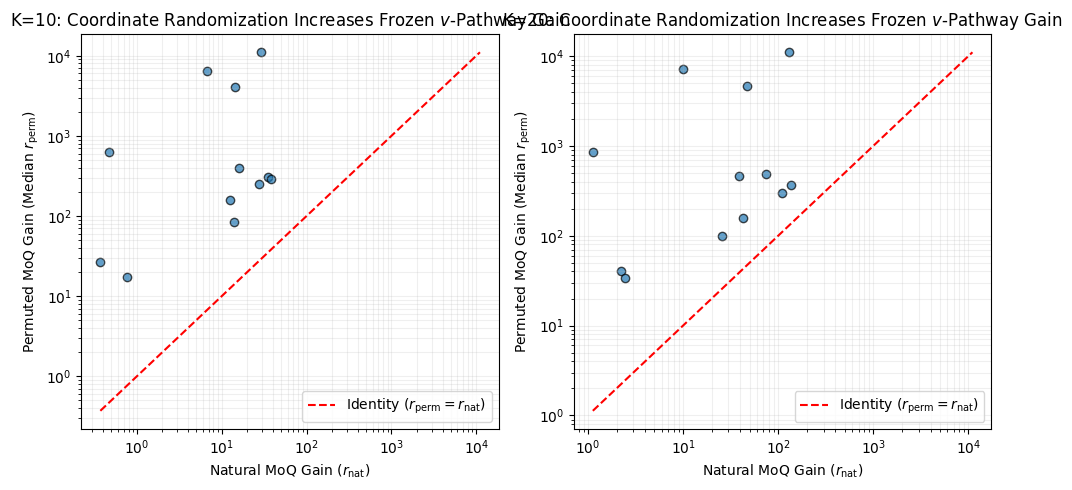

In [9]:
def plot_stage18c():
    plt.figure(figsize=(10, 5))
    
    for i, K in enumerate([10, 20]):
        plt.subplot(1, 2, i + 1)
        path = get_path(f"stage18c_K{K}_soap_moq.json")
        if not path.exists():
            plt.text(0.5, 0.5, f"Missing {path.name}", ha='center')
            continue
            
        with open(path, "r") as f:
            data = json.load(f)
            
        r_nats = []
        r_perms = []
        for rec in data:
            moq_dict = rec.get("moq_corrected_permutation", {})
            if "r_nat" in moq_dict and "r_perm_median" in moq_dict:
                r_nats.append(moq_dict["r_nat"])
                r_perms.append(moq_dict["r_perm_median"])
            
        if len(r_nats) > 0:
            plt.scatter(r_nats, r_perms, alpha=0.7, edgecolors='k')
            max_val = max(max(r_nats), max(r_perms))
            min_val = min(min(r_nats), min(r_perms))
            plt.plot([min_val, max_val], [min_val, max_val], 'r--', label=r'Identity ($r_{\mathrm{perm}} = r_{\mathrm{nat}}$)')
            
        plt.xscale('log')
        plt.yscale('log')
        plt.xlabel(r'Natural MoQ Gain ($r_{\mathrm{nat}}$)')
        plt.ylabel(r'Permuted MoQ Gain (Median $r_{\mathrm{perm}}$)')
        plt.title(f'K={K}: Coordinate Randomization Increases Frozen $v$-Pathway Gain')
        plt.legend()
        plt.grid(True, which="both", ls="-", alpha=0.2)
        
    plt.tight_layout()
    plt.show()

plot_stage18c()


## Figure 2: Stage 20A - Full Optimizer Transmission


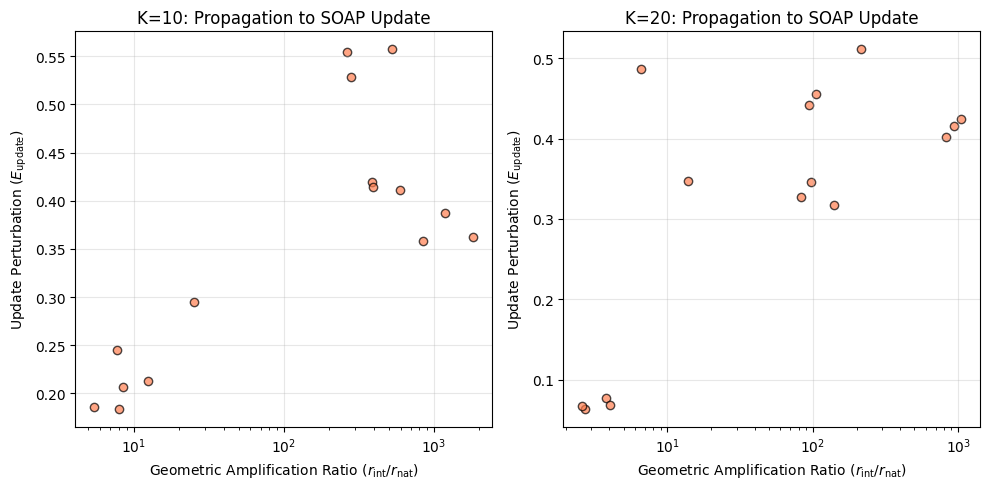

In [10]:
def plot_stage20a():
    plt.figure(figsize=(10, 5))
    
    for i, K in enumerate([10, 20]):
        plt.subplot(1, 2, i + 1)
        path = get_path(f"stage20a_K{K}_soap_moq.json")
        if not path.exists():
            continue
            
        with open(path, "r") as f:
            data = json.load(f)
            
        r_ratios = []
        e_updates = []
        for rec in data:
            if "r_ratio_median" in rec and "E_update_median" in rec:
                r_ratios.append(rec["r_ratio_median"])
                e_updates.append(rec["E_update_median"])
            
        if len(r_ratios) > 0:
            plt.scatter(r_ratios, e_updates, alpha=0.7, edgecolors='k', color='coral')
            plt.xscale('log')
            
        plt.xlabel(r'Geometric Amplification Ratio ($r_{\mathrm{int}} / r_{\mathrm{nat}}$)')
        plt.ylabel(r'Update Perturbation ($E_{\mathrm{update}}$)')
        plt.title(f'K={K}: Propagation to SOAP Update')
        plt.grid(True, alpha=0.3)
        
    plt.tight_layout()
    plt.show()

plot_stage20a()


## Figure 3: Stage 23 - Coupled Second-Moment Normalization Attenuates First-Moment Sensitivity


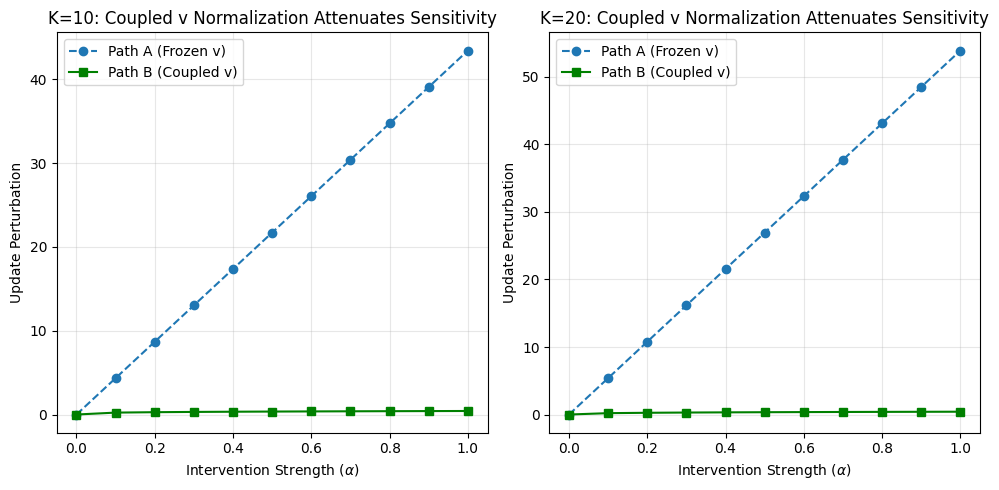

In [11]:
def plot_stage23():
    plt.figure(figsize=(10, 5))
    
    for i, K in enumerate([10, 20]):
        plt.subplot(1, 2, i + 1)
        path = get_path(f"stage23_K{K}_soap_moq.json")
        if not path.exists():
            continue
            
        with open(path, "r") as f:
            data = json.load(f)
            
        alpha_dict = {}
        for rec in data:
            if "alphas" in rec and "E_A_median" in rec and "E_B_median" in rec:
                alphas = rec["alphas"]
                eas = rec["E_A_median"]
                ebs = rec["E_B_median"]
                for a, ea, eb in zip(alphas, eas, ebs):
                    if a not in alpha_dict:
                        alpha_dict[a] = {"E_A": [], "E_B": []}
                    alpha_dict[a]["E_A"].append(ea)
                    alpha_dict[a]["E_B"].append(eb)
            
        if len(alpha_dict) > 0:
            alphas = sorted(list(alpha_dict.keys()))
            mean_EA = [np.mean(alpha_dict[a]["E_A"]) for a in alphas]
            mean_EB = [np.mean(alpha_dict[a]["E_B"]) for a in alphas]
            
            plt.plot(alphas, mean_EA, 'o--', label='Path A (Frozen v)')
            plt.plot(alphas, mean_EB, 's-', label='Path B (Coupled v)', color='green')
        
        plt.xlabel(r'Intervention Strength ($\alpha$)')
        plt.ylabel('Update Perturbation')
        plt.title(f'K={K}: Coupled v Normalization Attenuates Sensitivity')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
    plt.tight_layout()
    plt.show()

plot_stage23()


## Figure 4: Stage 26 - Overall dose-response relationship between geometric disruption and final error


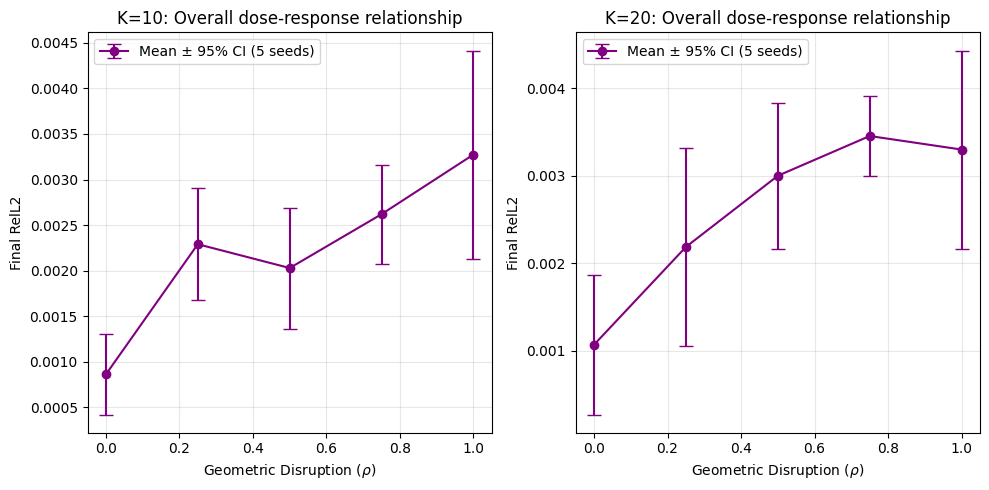

In [12]:
def plot_stage26():
    plt.figure(figsize=(10, 5))
    
    for i, K in enumerate([10, 20]):
        plt.subplot(1, 2, i + 1)
        path = get_path(f"stage26_K{K}_confirmatory.json")
        if not path.exists():
            continue
            
        with open(path, "r") as f:
            data = json.load(f)
            
        rhos = sorted([float(r) for r in data.keys()])
        mean_rels = []
        std_rels = []
        
        for rho in rhos:
            rho_str = str(rho) if str(rho) in data else str(float(rho))
            for key in data.keys():
                if abs(float(key) - rho) < 1e-4:
                    rho_str = key
                    break
            
            finals = []
            for seed in data[rho_str]["summaries"]:
                finals.append(data[rho_str]["summaries"][seed]["final_rel_l2"])
                
            mean_rels.append(np.mean(finals))
            # 95% CI is roughly mean +- 2.776 * SE (t-dist with 4 dof)
            se = np.std(finals, ddof=1) / np.sqrt(len(finals))
            ci_95 = 2.776 * se
            std_rels.append(ci_95)
            
        if len(rhos) > 0:
            plt.errorbar(rhos, mean_rels, yerr=std_rels, fmt='-o', capsize=5, color='purple', label='Mean ± 95% CI (5 seeds)')
            
        plt.xlabel(r'Geometric Disruption ($\rho$)')
        plt.ylabel('Final RelL2')
        plt.title(f'K={K}: Overall dose-response relationship')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
    plt.tight_layout()
    plt.show()

plot_stage26()


## Final Statistical Interpretation

Across K=10 and K=20, increasing coordinate-level disruption of the natural MoQ perturbation produced progressively larger update-space perturbations. Final PINN error was generally higher under stronger disruption, although the dose-response was not perfectly monotonic at every intermediate level. The repeated-measures analysis therefore supports a systematic association between geometric disruption and training outcome, rather than a strict monotonic law. The mechanism-to-outcome relationship is also positive within both K values. These results are specific to the tested 2D Poisson problem, architecture, and training configuration and should not be generalized to all PINNs without further validation.
